# Ad Spend Incrementality & Attribution Modeling

1. Generate or load campaign spend and conversions
2. Run incrementality (exposed vs control)
3. Multi-touch attribution (linear, time-decay, position-based)
4. Channel ROI summary

In [1]:
import sys
import pandas as pd
from pathlib import Path
sys.path.insert(0, str(Path("../scripts").resolve()))

from generate_sample_campaign_data import generate_campaign_spend, generate_conversions_and_touchpoints

data_dir = Path("../data").resolve()
data_dir.mkdir(parents=True, exist_ok=True)

if not (data_dir / "campaign_spend.csv").exists():
    spend = generate_campaign_spend()
    conv, tp = generate_conversions_and_touchpoints()
    spend.to_csv(data_dir / "campaign_spend.csv", index=False)
    conv.to_csv(data_dir / "conversions.csv", index=False)
    tp.to_csv(data_dir / "touchpoints.csv", index=False)
    print("Sample data generated.")
else:
    spend = pd.read_csv(data_dir / "campaign_spend.csv")
    conv = pd.read_csv(data_dir / "conversions.csv")
    tp = pd.read_csv(data_dir / "touchpoints.csv")
    print("Loaded existing data.")
print(spend.head(), conv.shape, tp.shape)

Sample data generated.
         date      channel  spend  impressions  clicks
0  2024-01-01  google_paid  42.31        19182     107
1  2024-01-01         meta  14.14        17428     103
2  2024-01-01     linkedin   9.93        37894      90
3  2024-01-01      organic  28.87         3251      98
4  2024-01-01        email   4.40        30159      94 (2000, 6) (4990, 5)


In [2]:
from attribution_models import load_touchpoints, linear_attribution, time_decay_attribution, channel_summary

tp = load_touchpoints(str(data_dir / "touchpoints.csv"))
tp["conversion_id"] = tp["conversion_id"].fillna(0).astype(int)
tp = tp[tp["conversion_id"] > 0]

linear = linear_attribution(tp)
summary_linear = channel_summary(linear)
summary_linear

,channel,attributed_conversions,touch_count
0,email,406.183333,1009
1,google_paid,368.966667,956
2,linkedin,394.633333,980
3,meta,426.066667,1046
4,organic,404.150000,999


In [3]:
decay = time_decay_attribution(tp, half_life_days=7)
summary_decay = channel_summary(decay)
summary_decay

,channel,attributed_conversions,touch_count
0,email,401.316431,1009
1,google_paid,365.081307,956
2,linkedin,404.073425,980
3,meta,425.991872,1046
4,organic,403.536964,999


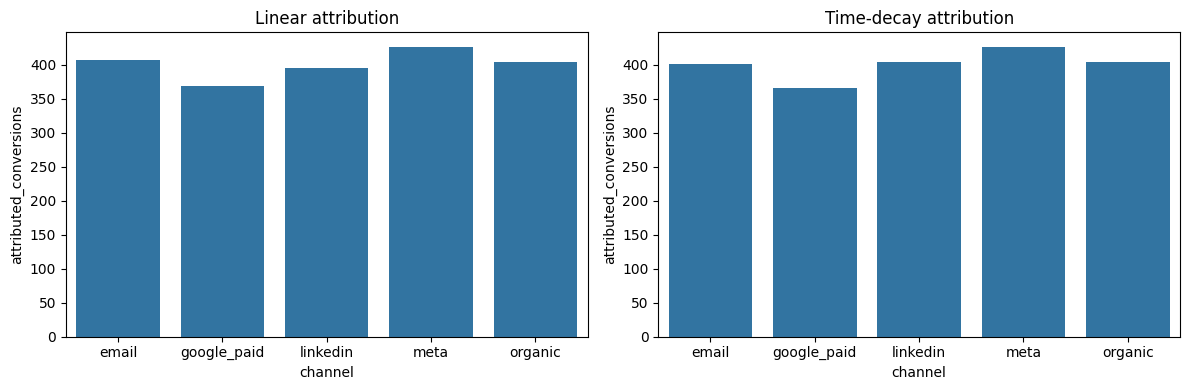

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=summary_linear, x="channel", y="attributed_conversions", ax=ax[0])
ax[0].set_title("Linear attribution")
sns.barplot(data=summary_decay, x="channel", y="attributed_conversions", ax=ax[1])
ax[1].set_title("Time-decay attribution")
plt.tight_layout()
plt.show()